<a href="https://colab.research.google.com/github/kyuhyunglee/Brain-to-Text-decoding-network/blob/main/BCIAdaptiveTransformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 필수 라이브러리 설치
!pip install einops
!pip install jiwer
!pip install -U sympy

# 구글 드라이브 마운트
from google.colab import drive
drive.mount('/content/drive')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 81.6 MB/s eta 0:00:00
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import glob
import scipy.io
import numpy as np
import torch
import math

# 구글 드라이브 기본 경로
rootDir = '/content/drive/MyDrive/handwritingBCI_data/doi_10_5061_dryad_wh70rxwmv__v20211015/handwritingBCIData_Unzipped/handwritingBCIData/'

# Step 2에서 처리했던 세션 리스트
dataDirs = ['t5.2019.05.08', 't5.2019.11.25', 't5.2019.12.09', 't5.2019.12.11', 't5.2019.12.18',
            't5.2019.12.20', 't5.2020.01.06', 't5.2020.01.08']

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

#A100/H100 사용 시 활성화
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
print("TF32 가속 모드 활성화됨")

🚀 A100/H100 TF32 가속 모드 활성화됨


/usr/local/lib/python3.12/dist-packages/torch/backends/__init__.py:46: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:80.)
  self.setter(val)


In [ ]:
%%writefile vit.py
import torch
from torch import nn
import torch.nn.functional as F
from einops import rearrange, repeat
import math

def drop_path(x, drop_prob: float = 0., training: bool = False):
    # 레이어 단위의 DropPath 구현
    if drop_prob == 0. or not training:
      return x
    keep_prob = 1 - drop_prob
    shape = (x.shape[0],) + (1,) * (x.ndim-1)
    random_tensor = keep_prob + torch.rand(shape, dtype=x.dtype, device=x.device)
    random_tensor.floor_()  # 0 or 1 binarize
    output = x.div(keep_prob) * random_tensor
    return output

class DropPath(nn.Module):
    def __init__(self, drop_prob=None):
        super(DropPath, self).__init__()
        self.drop_prob = drop_prob

    def forward(self, x):
        return drop_path(x, self.drop_prob, self.training)

class AdaptiveAttention(nn.Module):
    def __init__(self, dim, heads = 8, dim_head = 64, dropout = 0., rank = 8):
        super().__init__()
        inner_dim = dim_head * heads
        project_out = not (heads == 1 and dim_head == dim)

        self.heads = heads
        self.scale = dim_head ** -0.5

        self.norm = nn.LayerNorm(dim)
        self.attend = nn.Softmax(dim = -1)
        self.dropout = nn.Dropout(dropout)

        self.to_qkv = nn.Linear(dim, inner_dim * 3, bias = False)

        # --- Adaptive Bilinear Attention ---
        # W를 직접 학습하는 대신 U를 학습하여 W = U * U^T 로 정의
        self.U1 = nn.Parameter(torch.randn(heads, dim_head, rank))
        self.U2 = nn.Parameter(torch.randn(heads, rank, dim_head))
        nn.init.xavier_normal_(self.U1)
        nn.init.xavier_normal_(self.U2)

        self.last_g = None
        # ----------------------------------------------

        self.to_out = nn.Sequential(
            nn.Linear(inner_dim, dim),
            nn.Dropout(dropout)
        ) if project_out else nn.Identity()

    def forward(self, x, epoch=None):
        x = self.norm(x)
        qkv = self.to_qkv(x).chunk(3, dim = -1)
        q, k, v = map(lambda t: rearrange(t, 'b n (h d) -> b h n d', h = self.heads), qkv)

        # Dot-product Attention (I)
        I = torch.matmul(q, k.transpose(-1, -2)) * self.scale

        """
        # Confidence g 계산 (Q와 K의 분포 유사도를 통한 신뢰도 측정)
        # 각 토큰의 Q와 K 벡터 사이의 불확실성을 Cross-entropy 컨셉으로 측정
        기존에는 g값을 구하기 위해 CE를 썼으나, 이는 스케일 부적절
        학습 초기에는 g의 최솟값을 유지하도록 보장해서 데이터의 흐름을 베우게 한
        q_dist = F.softmax(q * self.scale, dim=-1)
        k_dist = F.softmax(k * self.scale, dim=-1)

        ce_loss = -torch.sum(q_dist * torch.log(k_dist + 1e-9), dim=-1)

        g = torch.exp(-ce_loss.mean(dim=-1, keepdim=True)).unsqueeze(-1)
        self.last_g = g.detach()
        """
        attn_I = torch.softmax(I, dim=-1)
        # Shannon Entropy를 이용한 확신도 측정
        entropy = -torch.sum(attn_I * torch.log(attn_I + 1e-9), dim=-1)
        max_entropy = torch.log(torch.tensor(attn_I.shape[-1], dtype=torch.float32))

        # 엔트로피가 낮을수록 g가 1에 가깝게 설계
        g_prob = 1.0 - (entropy.mean(dim=-1, keepdim=True) / max_entropy)
        g_prob = g_prob.unsqueeze(-1)

        # g가 너무 낮아져서 W에 매몰되는 것을 방지하기 위한 하한선
        # 초기(0 epoch)에는 0.5에서 시작하여, 100 epoch 근처에서 0.01로 수렴하게 설계
        if epoch is not None:
            curr_epoch = epoch.item() if isinstance(epoch, torch.Tensor) else epoch
            floor = 0.01 + (0.49 * math.exp(-0.05 * curr_epoch))
        else:
            floor = 0.01

        g = torch.maximum(g_prob, torch.tensor(floor, device=x.device))
        self.last_g = g.detach()

        # Bilinear Attention
        # Q * W * K^T
        U = torch.matmul(self.U1, self.U2)
        q_u = torch.matmul(q, U)
        k_u = torch.matmul(k, U)

        W_score = torch.matmul(q_u, k_u.transpose(-1, -2)) * self.scale

        scores = (g * I + (1 - g) * W_score)

        attn = self.attend(scores)
        attn = self.dropout(attn)

        out = torch.matmul(attn, v)
        out = rearrange(out, 'b h n d -> b n (h d)')
        return self.to_out(out)

class Transformer(nn.Module):
    def __init__(self, dim, depth, heads, dim_head, mlp_dim, dropout = 0., drop_path_rate = 0.2):
        super().__init__()
        self.layers = nn.ModuleList([])

        # 레이어 깊이에 따라 선형적으로 DropPath 확률을 높인다.
        dpr = [x.item() for x in torch.linspace(0, drop_path_rate, depth)]

        for i in range(depth):
            self.layers.append(nn.ModuleList([
                AdaptiveAttention(dim, heads = heads, dim_head = dim_head, dropout = dropout),
                nn.Sequential(
                    nn.LayerNorm(dim),
                    nn.Linear(dim, mlp_dim),
                    nn.GELU(),
                    nn.Dropout(dropout),
                    nn.Linear(mlp_dim, dim),
                    nn.Dropout(dropout)
                ),
                DropPath(dpr[i])
            ]))
    def forward(self, x, epoch=None):
        for attn, ff, dpath in self.layers:
            # Residual Connection에 DropPath 적용
            x = x + dpath(attn(x, epoch=epoch))
            x = x + dpath(ff(x))
        return x

Writing vit.py


In [ ]:
import torch
from torch import nn # nn 모듈 추가
from einops.layers.torch import Rearrange # Rearrange 추가
from vit import Transformer

# 100ms 단위로 뇌의 변화를 포착하기 위해
# patch_size는 20으로 한다- 단위 시간은 200ms이다.
class NeuralTransformer(nn.Module):
    def __init__(self, *, num_time_bins=12000, num_electrodes=192, patch_size=20,
                 num_classes=32, dim=384, depth=6, heads=6, mlp_dim=1536,
                 dropout=0.35, input_dropout=0.2):
        super().__init__()

        self.patch_size = patch_size
        self.dim = dim

        # Patch Embedding
        # (Batch, Time, Channel) -> (Batch, Time//P, Dim)
        patch_input_dim = num_electrodes * patch_size

        self.to_patch_embedding = nn.Sequential(
            Rearrange('b (n p) c -> b n (p c)', p=patch_size),
            nn.LayerNorm(patch_input_dim),
            nn.Linear(patch_input_dim, dim),
            nn.LayerNorm(dim),
        )

        # Positional Embedding
        self.num_patches = num_time_bins // patch_size
        self.pos_embedding = nn.Parameter(torch.randn(1, self.num_patches, dim))
        self.input_dropout = nn.Dropout(input_dropout)

        # Transformer Encoder
        self.transformer = Transformer(
            dim=dim,
            depth=depth,
            heads=heads,
            dim_head=dim // heads,
            mlp_dim=mlp_dim,
            dropout=dropout
        )

        # Final Output Head
        self.to_latent = nn.LayerNorm(dim)
        self.char_head = nn.Linear(dim, 31)
        self.start_head = nn.Linear(dim, 1)

    def forward(self, x, epoch=None):
        # x: (Batch, Time_Bins, Channels)
        # 1, Patch Embedding
        x = self.to_patch_embedding(x)
        b, n, _ = x.shape

        x += self.pos_embedding[:, :n, :]

        x = self.input_dropout(x)

        # 2. Transformer Blocks
        x = self.transformer(x, epoch=epoch)

        # 3. Output
        x = self.to_latent(x)

        char_logits = self.char_head(x)   # (Batch, Time, 31)
        start_logits = self.start_head(x) # (Batch, Time, 1)

        return char_logits, start_logits


In [ ]:
import os
import glob
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader # Dataset 임포트 추가
from torch.nn.utils.rnn import pad_sequence
import scipy.io

# 1. 연구 논문 알고리즘 기반 Time-Masking 함수
def apply_time_masking(x, N=20, M=0.075):
    """
    x: (L, C) 형태의 텐서 (Time x Channels)
    N: 마스크 개수, M: 최대 마스크 길이 비율
    """
    L, C = x.shape
    F = int(M * L)
    x_masked = x.clone()

    for _ in range(N):
        if L - F <= 0: continue
        S = torch.randint(0, L - F, (1,)).item() # 시작점
        D = torch.randint(0, F, (1,)).item()     # 길이
        x_masked[S : S + D, :] = 0.0             # 마스킹 (0으로 대체)

    return x_masked

class BCIMatDataset(Dataset):
    def __init__(self, session_list, root_dir, mode='train', apply_mask=True, max_bins=12000):
        self.inputs = []
        self.labels = []
        self.texts = []
        self.mode = mode
        self.apply_mask = apply_mask
        self.max_bins = max_bins

        # 파티션 정보 로드 (Hold-out 설정)
        partition_path = os.path.join(root_dir, 'RNNTrainingSteps', 'trainTestPartitions_HeldOutTrials.mat')
        partitions = scipy.io.loadmat(partition_path)
        print(f" {len(session_list)}개 세션 데이터 로드 및 32채널 라벨 정렬 시작...")
        skipped_count = 0

        for session in session_list:
            try:
                # 파일 로드
                feat_path = os.path.join(root_dir, 'Datasets', session, 'sentences.mat')
                label_path = os.path.join(root_dir, 'RNNTrainingSteps', 'Step2_HMMLabels', 'HeldOutTrials', f'{session}_timeSeriesLabels.mat')

                feat_mat = scipy.io.loadmat(feat_path)
                label_mat = scipy.io.loadmat(label_path)

                # 기본 데이터 추출
                neural_cube = feat_mat['neuralActivityCube'].astype(np.float32)
                prompts = feat_mat['sentencePrompt']
                num_trials = neural_cube.shape[0]

                # 라벨 데이터 추출
                char_probs = label_mat['charProbTarget']
                char_starts = label_mat['charStartTarget']
                valid_bins = label_mat['timeBinsPerSentence'].flatten()

                # Dimension Fix
                if char_probs.shape[0] != num_trials and char_probs.shape[1] == num_trials:
                     char_probs = np.transpose(char_probs, (1, 0, 2))
                if char_starts.shape[0] != num_trials and char_starts.shape[1] == num_trials:
                    char_starts = char_starts.T

                # 신경망 데이터 log 변환 후 정규화 (Z-score)
                neural_cube = np.log(neural_cube + 1.0)

                global_mean = np.mean(neural_cube)
                global_std = np.std(neural_cube)

                if global_std == 0: global_std = 1.0
                neural_cube = (neural_cube - global_mean) / global_std

                # Train/Test Split
                if mode == 'train':
                    target_idx = partitions[f'{session}_train'].flatten() - 1
                else:
                    train_idx = partitions[f'{session}_train'].flatten() - 1
                    all_idx = np.arange(len(neural_cube))
                    target_idx = np.setdiff1d(all_idx, train_idx)

                # 데이터 패딩 및 32채널 병합
                for i in target_idx:
                    length = min(valid_bins[i], self.max_bins)
                    snippet_probs = char_probs[i, :length, :]

                    predicted_classes = np.argmax(snippet_probs, axis=1)
                    unique_classes = np.unique(predicted_classes)

                    # 라벨링 이상하게 된 거 제외하면 test/val이 너무 적어짐
                    if length > 50 and len(unique_classes) < 2:
                        skipped_count += 1
                        continue

                    # 정상 데이터만 추가
                    feat_pad = np.zeros((self.max_bins, 192), dtype=np.float32)
                    targ_pad = np.zeros((self.max_bins, 32), dtype=np.float32)
                    targ_pad[:, 26] = 1.0

                    feat_pad[:length, :] = neural_cube[i, :length, :]
                    targ_pad[:length, :31] = snippet_probs
                    targ_pad[:length, 31] = char_starts[i, :length]

                    self.inputs.append(feat_pad)
                    self.labels.append(targ_pad)

                    try:
                        self.texts.append(prompts[i][0][0])
                    except:
                        self.texts.append("Unknown")

            except Exception as e:
                print(f" 세션 {session} 로드 실패: {e}")

        print(f" {mode.upper()} 로드 완료: {len(self.inputs)}개 ( 고착된 샘플 {skipped_count}개 제거됨)")

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, idx):
        x = torch.from_numpy(self.inputs[idx]) # (12000, 192)
        y = torch.from_numpy(self.labels[idx]) # (12000, 32)

        # 200ms 해상도로 샘플링
        y_32 = y[::10, :]

        # 학습 모드이고 Time-Masking 적용 시
        if self.apply_mask and self.mode == 'train':
            x = apply_time_masking(x, N=20, M=0.075)

        return x, y_32, self.texts[idx]

In [ ]:
import numpy as np
import scipy.io
import os

def create_snippet_library(session_list, root_dir, train_indices_dict=None):
    snippet_lib = {i: [] for i in range(31)} # 31개 클래스별 리스트

    partition_path = os.path.join(root_dir, 'RNNTrainingSteps', 'trainTestPartitions_HeldOutTrials.mat')

    print(" 글자 조각(Snippet) 추출 시작...")
    for session in session_list:
        # 원본 데이터 및 라벨 로드
        feat_path = os.path.join(root_dir, 'Datasets', session, 'sentences.mat')
        label_path = os.path.join(root_dir, 'RNNTrainingSteps', 'Step2_HMMLabels', 'HeldOutTrials', f'{session}_timeSeriesLabels.mat')

        feat_mat = scipy.io.loadmat(feat_path)
        partition_mat = scipy.io.loadmat(partition_path)
        label_mat = scipy.io.loadmat(label_path)

        # 클래스 내부와 동일하게 train_idx 추출 (1차감 필수)
        train_idx = partition_mat[f'{session}_train'].flatten() - 1

        neural_cube = feat_mat['neuralActivityCube'].astype(np.float32)
        neural_cube = (neural_cube - neural_cube.mean()) / (neural_cube.std() + 1e-6)

        # Step 2에서 생성된 글자 시작 지점 정보
        char_probs = label_mat['charProbTarget']
        if char_probs.shape[1] == neural_cube.shape[0]: # (Time, Trials, 31)
            char_probs = np.transpose(char_probs, (1, 0, 2))
        elif char_probs.shape[2] == neural_cube.shape[0]: # (Time, 31, Trials)
            char_probs = np.transpose(char_probs, (2, 0, 1))

        letter_starts = label_mat['letterStarts'] # (Sentences, MaxLetters)
        letter_durations = label_mat['letterDurations'] # (Sentences, MaxLetters)

        # 해당 세션에서 Train에 할당된 인덱스만 추출
        for s in train_idx:
            for l in range(letter_starts.shape[1]):
                start = int(letter_starts[s, l])
                dur = int(letter_durations[s, l])

                if dur > 0:
                    mid_time = start + dur // 2
                    char_idx = np.argmax(char_probs[s, mid_time, :31])

                    snippet = neural_cube[s, start:start+dur, :]
                    snippet_lib[char_idx].append(snippet)

    for i in range(31):
        print(f"Char {i}: {len(snippet_lib[i])} snippets", end=' | ')
    return snippet_lib

def debug_dataset_labels(dataset, num_samples=3):
    print(f"\n{'='*20} 데이터셋 라벨 무결성 점검 {'='*20}")
    for _ in range(num_samples):
        idx = np.random.randint(len(dataset))
        _, labels, text = dataset[idx] # labels: (120, 32)

        # 각 타임스텝(1200개)에서 가장 확률이 높은 클래스 추출
        active_indices = torch.argmax(labels[:, :31], dim=-1).unique().tolist()
        print(f"Index: {idx} | Text: {text}")
        print(f"Detected Indices in GT: {active_indices}")
        if len(active_indices) < 3:
            print("경고: 라벨에 포함된 문자가 너무 적습니다. 차원 정렬을 확인하세요.")

In [ ]:
import torch
import numpy as np
import random
from torch.utils.data import Dataset, DataLoader
from scipy.signal import resample

class SyntheticBCIDataset(Dataset):
    def __init__(self, snippet_lib, num_synthetic_sentences=5120, max_bins=12000):
        self.snippet_lib = snippet_lib
        self.num_samples = num_synthetic_sentences
        self.max_bins = max_bins

        self.char_list = [
            'a','b','c','d','e','f','g','h','i','j','k','l','m','n','o','p','q','r','s','t','u','v','w','x','y','z',
            '>', ',', "'", '~', '?'
        ]
        self.blank_idx = 26
        # '>' 가 공백/침묵 역할

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        # 빈 캔버스 생성 (32개 채널: 31개 문자 + 1개 START)
        synth_feat = np.zeros((self.max_bins, 192), dtype=np.float32)
        synth_label = np.zeros((self.max_bins, 32), dtype=np.float32)

        # 모든 구간을 '>' (인덱스 26)로 채움
        synth_label[:, self.blank_idx] = 1.0

        current_bin = 50 # 초기 여유분
        true_chars = []

        # 랜덤하게 글자 조립
        while current_bin < self.max_bins - 150:
            # 공백을 제외한 나머지 인덱스 중 하나 선택
            available_indices = [i for i in range(31) if i != self.blank_idx]
            c_idx = random.choice(available_indices)

            if len(self.snippet_lib[c_idx]) == 0: continue

            snippet = random.choice(self.snippet_lib[c_idx])

            # Time Dilation (속도 변형)
            # 원본 길이를 0.8 ~ 1.2배로 랜덤하게 늘리거나 줄임
            stretch_factor = np.random.uniform(0.8, 1.2)
            new_len = int(len(snippet) * stretch_factor)

            # 간단한 선형 보간 (Linear Interpolation)을 이용해 리샘플링
            snippet = resample(snippet, new_len)
            s_len = new_len

            # Neural Input Delay (10~15 bins = 100~150ms)
            # 뇌 신호보다 라벨이 늦게 나타나도록 설정
            delay = np.random.randint(10, 16)

            # Label이 기록될 위치
            label_start = current_bin + delay
            label_end = label_start + s_len

            # Feature와 Label이 모두 캔버스 안에 있어야 함
            if label_end > self.max_bins - 50:
                break

            # 신호 자체에 변형 가하기
            aug_snippet = snippet.copy()

            # White Noise 추가
            noise = np.random.randn(*aug_snippet.shape) * 0.5
            aug_snippet += noise.astype(np.float32)

            # Constant Offset Drift
            # (1, 192) 크기의 랜덤 오프셋을 생성하여 더함
            offset = np.random.randn(1, 192) * 0.2
            aug_snippet += offset.astype(np.float32)

            # 데이터 삽입
            synth_feat[current_bin:current_bin+s_len, :] = snippet

            # 문자 라벨 (기존의 '>' 라벨 1.0을 0.0으로 밀어내고 해당 문자 1.0)
            # 또한 라벨을 신호에서 조금 지연된 위치에 넣는다
            synth_label[label_start:label_end, self.blank_idx] = 0.0
            synth_label[label_start:label_end, c_idx] = 1.0

            # START 신호 삽입
            # 20 bins = 200ms (10ms bin 기준)
            start_end_bin = min(label_start + 20, self.max_bins)
            synth_label[label_start:start_end_bin, 31] = 1.0

            # 텍스트 기록
            char = self.char_list[c_idx]
            true_chars.append(' ' if char == '>' else char)

            # 다음 글자 위치로 이동 (글자 사이 간격 100~300ms)
            current_bin += s_len + np.random.randint(10, 30)

        # 3. 200ms 패치 단위로 샘플링
        x = torch.from_numpy(synth_feat)
        y_32 = torch.from_numpy(synth_label)[::10, :]

        true_text = "".join(true_chars)

        return x, y_32, true_text

In [ ]:
import copy
import torch
import numpy as np
import scipy.io
import os
from torch.utils.data import DataLoader, Subset, ConcatDataset, random_split
from sklearn.model_selection import train_test_split

all_sessions = dataDirs

# 데이터셋 로드
ds_train_full = BCIMatDataset(all_sessions, rootDir, mode='train', apply_mask=True)
ds_test_full = BCIMatDataset(all_sessions, rootDir, mode='test', apply_mask=False)

# Snippet 추출
snippet_lib = create_snippet_library(all_sessions, rootDir)

# 합성 데이터 생성 및 결합
train_synth_dataset = SyntheticBCIDataset(snippet_lib, num_synthetic_sentences=10240)
train_dataset = ConcatDataset([ds_train_full]*10 + [train_synth_dataset])

# Validation / Test 분할
test_total = len(ds_test_full)
val_set, test_set = random_split(
    ds_test_full,
    [test_total//2, test_total - test_total//2],
    generator=torch.Generator().manual_seed(42)
)

# DataLoader 설정
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_set, batch_size=32, shuffle=False)
test_loader  = DataLoader(test_set, batch_size=32, shuffle=False)

print(f"\n✅ 파이프라인 준비 완료")
print(f"   - Train (Real+Synth): {len(train_dataset)}")
print(f"   - Val: {len(val_set)} | Test: {len(test_set)}")

# 정합성 체크
#debug_dataset_labels(train_dataset)

 8개 세션 데이터 로드 및 32채널 라벨 정렬 시작...
 TRAIN 로드 완료: 499개 ( 고착된 샘플 23개 제거됨)
 8개 세션 데이터 로드 및 32채널 라벨 정렬 시작...
 TEST 로드 완료: 82개 ( 고착된 샘플 94개 제거됨)
 글자 조각(Snippet) 추출 시작...
Char 0: 1759 snippets | Char 1: 367 snippets | Char 2: 639 snippets | Char 3: 867 snippets | Char 4: 2834 snippets | Char 5: 473 snippets | Char 6: 479 snippets | Char 7: 1264 snippets | Char 8: 1517 snippets | Char 9: 46 snippets | Char 10: 208 snippets | Char 11: 915 snippets | Char 12: 498 snippets | Char 13: 1457 snippets | Char 14: 1593 snippets | Char 15: 450 snippets | Char 16: 38 snippets | Char 17: 1320 snippets | Char 18: 1418 snippets | Char 19: 2034 snippets | Char 20: 635 snippets | Char 21: 239 snippets | Char 22: 540 snippets | Char 23: 54 snippets | Char 24: 445 snippets | Char 25: 34 snippets | Char 26: 4531 snippets | Char 27: 129 snippets | Char 28: 94 snippets | Char 29: 450 snippets | Char 30: 51 snippets | 
✅ 파이프라인 준비 완료
   - Train (Real+Synth): 15230
   - Val: 41 | Test: 41


In [ ]:
import os
import random
import gc
import shutil
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.amp import autocast, GradScaler
from torch.optim.lr_scheduler import OneCycleLR
from torch.utils.data import DataLoader

print("GPU 메모리 및 변수 정리 중...")

# 삭제할 변수 목록
vars_to_delete = ['model', 'optimizer', 'scaler', 'scheduler', 'train_loader', 'val_loader']

# globals()에 변수가 존재할 때만 삭제 (Not Defined 에러 방지)
for var_name in vars_to_delete:
    if var_name in globals():
        del globals()[var_name]

# 가비지 컬렉션 및 CUDA 캐시 비우기
gc.collect()
torch.cuda.empty_cache()

# 현재 메모리 상태 확인
if torch.cuda.is_available():
    free_mem, total_mem = torch.cuda.mem_get_info()
    print(f"✨ 메모리 확보 완료: {free_mem/1024**3:.2f}GB / {total_mem/1024**3:.2f}GB 사용 가능")

# ---  논문 사양 하이퍼파라미터 및 설정 ---
num_epochs = 200
batch_size = 32
accumulation_steps = 2
initial_lr = 1e-3
weight_decay = 0.05
patch_size = 10

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

# 하드웨어 가속 설정
torch.set_float32_matmul_precision('high')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# --- 모델 인스턴스화 ---
model = NeuralTransformer(
    num_time_bins=12000,
    num_electrodes=192,
    patch_size=patch_size,
    num_classes=32,
    dim=384,
    depth=6,
    heads=6,
    mlp_dim=1536,
    dropout=0.2,
    input_dropout=0.3
).to(device)


# 체크포인트 설정
checkpoint_dir = '/content/drive/MyDrive/handwritingBCI_data/model_checkpoints'
last_ckpt_path = os.path.join(checkpoint_dir, 'adaptive_transformer_last.pth')
best_ckpt_path = os.path.join(checkpoint_dir, 'adaptive_transformer_best.pth')
os.makedirs(checkpoint_dir, exist_ok=True)

def save_ckpt(state, is_best=False):
    """
    안전한 저장을 위해:
    1. Colab 로컬에 먼저 저장
    2. 로컬 파일을 구글 드라이브로 복사 (shutil.copy)
    """
    # 1. 임시 파일명 설정 (Colab 로컬 경로 /content/...)
    temp_last_path = '/content/temp_adaptive_transformer_last.pth'
    temp_best_path = '/content/temp_adaptive_transformer_best.pth'

    try:
        # 2. 로컬에 먼저 저장 (메모리 문제 최소화)
        torch.save(state, temp_last_path)

        # 3. 구글 드라이브로 복사 (last)
        if os.path.exists(checkpoint_dir):
            shutil.copy(temp_last_path, last_ckpt_path)

        # 4. Best 모델일 경우 동일하게 처리
        if is_best:
            torch.save(state, temp_best_path) # 로컬에 best도 저장
            if os.path.exists(checkpoint_dir):
                shutil.copy(temp_best_path, best_ckpt_path)
            print(f" 최저 Validation Loss 달성! 모델 안전 저장 완료.")

    except Exception as e:
        print(f"저장 중 오류 발생 (하지만 학습은 계속됨): {e}")
        # 로컬에라도 남아있으면 나중에 수동 복구 가능하므로 치명적이지 않음

def load_ckpt(model, optimizer, scheduler, scaler):
    if os.path.exists(last_ckpt_path):
        print(" [LOAD] 체크포인트에서 재개합니다...")
        ckpt = torch.load(last_ckpt_path)
        model.load_state_dict(ckpt['state_dict'])
        optimizer.load_state_dict(ckpt['optimizer'])
        scheduler.load_state_dict(ckpt['scheduler'])
        scaler.load_state_dict(ckpt['scaler'])

        loaded_best = ckpt.get('best_val_loss', float('inf'))
        loaded_history = ckpt.get('history', {
            'train_loss': ckpt.get('losses', []),
            'val_loss': [], 'train_acc': [], 'val_acc': []
        })

        return ckpt['epoch'], ckpt['global_step'], loaded_history, loaded_best

    return 0, 0, {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}, float('inf')

GPU 메모리 및 변수 정리 중...
✨ 메모리 확보 완료: 78.83GB / 79.25GB 사용 가능


In [ ]:
# Bilinear 파라미터 (U1, U2)에 강한 규제 적용
# 파라미터 그룹 분리
bilinear_params = []
other_params = []

for name, param in model.named_parameters():
    if param.requires_grad:
        # AdaptiveAttention 내부의 U 행렬 식별
        if 'U1' in name or 'U2' in name:
            bilinear_params.append(param)
        else:
            other_params.append(param)

print(f" Parameter Grouping:")
print(f"   - Bilinear Params (Strong Regularization): {len(bilinear_params)} tensors")
print(f"   - Other Params (Standard Regularization): {len(other_params)} tensors")

# Optimizer 설정 (Bilinear에 Weight Decay 3배 적용)
optimizer = optim.AdamW([
    {'params': other_params, 'weight_decay': weight_decay},
    {'params': bilinear_params, 'weight_decay': weight_decay * 3.0}
], lr=initial_lr)

# 손실 함수 및 옵티마이저 초기화
criterion_char = nn.CrossEntropyLoss(reduction='none', label_smoothing=0.1)
criterion_start = nn.MSELoss(reduction='none')

optimizer = optim.AdamW(model.parameters(), lr=initial_lr, weight_decay=weight_decay)
scaler = GradScaler()

START_LOSS_WEIGHT = 10.0

total_steps = num_epochs * len(train_loader)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.1,
    patience=10,
    min_lr=1e-6,
)

# --- 학습 루프 ---
start_epoch, global_step, loaded_history, best_val_loss = load_ckpt(model, optimizer, scheduler, scaler)

if isinstance(loaded_history, dict) and 'train_loss' in loaded_history:
    history = loaded_history
    if 'train_acc' not in history: history['train_acc'] = []
    if 'val_acc' not in history: history['val_acc'] = []
else:
    # train_losses가 리스트인 경우를 대비한 예외 처리
    history = {
        'train_loss': loaded_history if isinstance(loaded_history, list) else [],
        'val_loss': [],
        'train_acc': [],
        'val_acc': []
    }

print(f" 논문 사양 학습 시작 | 장치: {device}")
print(f" 총 문장 수: {len(train_dataset)} | 배치 당 스텝 수: {len(train_loader)}")

for epoch in range(start_epoch, num_epochs):
    model.train()
    epoch_train_loss = 0.0

    train_correct = 0
    train_total = 0

    for step, batch in enumerate(train_loader):
        inputs, targets, texts = batch
        inputs = inputs.to(device)
        targets = targets.to(device)

        raw_mask = (torch.abs(inputs).sum(dim=-1) > 1e-6).float()
        patch_mask = F.max_pool1d(raw_mask.unsqueeze(1), kernel_size=10, stride=10).squeeze(1)

        #targets_sampled = targets[:, ::2, :]
        targets_sampled = targets
        targets_char = targets_sampled[:, :, :31]
        targets_start = targets_sampled[:, :, 31:32]
        target_char_indices = torch.argmax(targets_char, dim=-1)

        optimizer.zero_grad()

        with autocast('cuda'):
            # Forward
            char_logits, start_logits = model(inputs, epoch=epoch)

            # Character Loss
            char_loss_raw = criterion_char(char_logits.transpose(1, 2), target_char_indices)

            # Start Signal Loss
            start_probs = torch.sigmoid(start_logits)
            start_loss_raw = criterion_start(start_probs, targets_start) # (B, T, 1)
            start_loss_raw = start_loss_raw.squeeze(-1) # (B, T)

            # Total Loss
            active_elements = patch_mask.sum()

            loss_char = (char_loss_raw * patch_mask).sum() / (active_elements + 1e-6)
            loss_start = (start_loss_raw * patch_mask).sum() / (active_elements + 1e-6)

            loss = loss_char + (START_LOSS_WEIGHT * loss_start)
            loss = loss / accumulation_steps

        if torch.isnan(loss) or torch.isinf(loss):
            print("Warning: Loss is NaN/Inf. Skipping step.")
            continue

        scaler.scale(loss).backward()

        if (step + 1) % accumulation_steps == 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

            epoch_train_loss += loss.item() * accumulation_steps
        else:
            epoch_train_loss += loss.item() * accumulation_steps

        global_step += 1

        with torch.no_grad():
            preds_char = torch.argmax(char_logits, dim=-1) # (B, T)
            correct_matrix = (preds_char == target_char_indices) & (patch_mask.bool())
            train_correct += correct_matrix.sum().item()
            train_total += active_elements.item()

        if step % 50 == 0:
            print(f"Ep {epoch+1} | Step {step} | Loss: {loss.item():.4f} | LR: {scheduler.get_last_lr()[0]:.6f}")

    #scheduler.step()

    # 에폭 종료 후 Validation 측정 추가
    model.eval()
    epoch_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch in val_loader:
            v_inputs, v_targets, _ = batch
            v_inputs = v_inputs.to(device)
            v_targets = v_targets.to(device)

            v_raw_mask = (torch.abs(v_inputs).sum(dim=-1) > 1e-6).float()
            v_patch_mask = F.max_pool1d(v_raw_mask.unsqueeze(1), kernel_size=10, stride=10).squeeze(1)

            #v_targets_sampled = v_targets[:, ::2, :]
            v_targets_sampled = v_targets
            v_targets_char = v_targets_sampled[:, :, :31]
            v_targets_start = v_targets_sampled[:, :, 31:32]
            v_target_char_indices = torch.argmax(v_targets_char, dim=-1)

            # Forward
            v_char_logits, v_start_logits = model(v_inputs)

            # Masked Loss
            v_char_loss_raw = criterion_char(v_char_logits.transpose(1, 2), v_target_char_indices)
            v_start_probs = torch.sigmoid(v_start_logits)
            v_start_loss_raw = criterion_start(v_start_probs, v_targets_start).squeeze(-1)

            v_active = v_patch_mask.sum()
            v_loss_char = (v_char_loss_raw * v_patch_mask).sum() / (v_active + 1e-6)
            v_loss_start = (v_start_loss_raw * v_patch_mask).sum() / (v_active + 1e-6)

            v_total_loss = v_loss_char + (START_LOSS_WEIGHT * v_loss_start)
            epoch_val_loss += v_total_loss.item()

            # Masked Accuracy
            v_preds = torch.argmax(v_char_logits, dim=-1)
            v_correct_mat = (v_preds == v_target_char_indices) & (v_patch_mask.bool())
            val_correct += v_correct_mat.sum().item()
            val_total += v_active.item()

            del v_inputs, v_targets, v_char_logits, v_start_logits, v_preds

    avg_train_loss = epoch_train_loss / len(train_loader)
    avg_val_loss = epoch_val_loss / len(val_loader) if len(val_loader) > 0 else 0
    avg_train_acc = (train_correct / train_total * 100) if train_total > 0 else 0.0
    avg_val_acc = (val_correct / val_total * 100) if val_total > 0 else 0.0

    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    history['train_acc'].append(avg_train_acc)
    history['val_acc'].append(avg_val_acc)

    scheduler.step(avg_val_loss)

    # BEST MODEL CHECK & SAVE
    # 현재 에폭의 검증 손실이 기존 최저치보다 낮으면 저장
    is_best = avg_val_loss < best_val_loss
    if is_best:
        best_val_loss = avg_val_loss

    ckpt_payload = {
        'epoch': epoch + 1,
        'global_step': global_step,
        'state_dict': model.state_dict(),
        'optimizer': optimizer.state_dict(),
        'scheduler': scheduler.state_dict(),
        'scaler': scaler.state_dict(),
        'losses': history['train_loss'],
        'history': history,
        'best_val_loss': best_val_loss
    }

    # 에포크마다 저장
    save_ckpt(ckpt_payload, is_best=is_best)

    try:
        del v_inputs, v_targets, v_char_logits, v_start_logits, v_preds, v_correct_mat
    except NameError:
        pass
    import gc
    gc.collect()
    torch.cuda.empty_cache()

    print(f"✅ Epoch {epoch+1} 종료 | Train: {avg_train_loss:.4f} | Val: {avg_val_loss:.4f} (Best: {best_val_loss:.4f})\n")

 Parameter Grouping:
   - Bilinear Params (Strong Regularization): 12 tensors
   - Other Params (Standard Regularization): 79 tensors
 [LOAD] 체크포인트에서 재개합니다...
 논문 사양 학습 시작 | 장치: cuda
 총 문장 수: 15230 | 배치 당 스텝 수: 476
Ep 16 | Step 0 | Loss: 0.9583 | LR: 0.001000
Ep 16 | Step 50 | Loss: 0.9559 | LR: 0.001000
Ep 16 | Step 100 | Loss: 0.9147 | LR: 0.001000
Ep 16 | Step 150 | Loss: 0.9065 | LR: 0.001000
Ep 16 | Step 200 | Loss: 0.9311 | LR: 0.001000
Ep 16 | Step 250 | Loss: 0.9258 | LR: 0.001000
Ep 16 | Step 300 | Loss: 0.9079 | LR: 0.001000
Ep 16 | Step 350 | Loss: 0.9366 | LR: 0.001000
Ep 16 | Step 400 | Loss: 0.9068 | LR: 0.001000
Ep 16 | Step 450 | Loss: 0.9260 | LR: 0.001000
✅ Epoch 16 종료 | Train: 1.8569 | Val: 3.1464 (Best: 3.0730)

Ep 17 | Step 0 | Loss: 0.9185 | LR: 0.001000
Ep 17 | Step 50 | Loss: 0.9070 | LR: 0.001000
Ep 17 | Step 100 | Loss: 0.9055 | LR: 0.001000
Ep 17 | Step 150 | Loss: 0.9263 | LR: 0.001000
Ep 17 | Step 200 | Loss: 0.9100 | LR: 0.001000
Ep 17 | Step 250 | Loss: 0

KeyboardInterrupt: 

In [ ]:
def greedy_decode(char_logits, start_logits, threshold=0.2, min_dist=3):
    """
    Start Signal을 트리거로 사용하여 문자를 디코딩합니다.
    - Start Signal 확률이 threshold를 넘고,
    - 동시에 Local Peak일 때만 문자를 인식합니다.
    """
    # 데이터 준비
    # char_logits: (Time, 31) -> 가장 높은 확률의 문자 인덱스 추출
    pred_indices = torch.argmax(char_logits, dim=-1).cpu().numpy()

    # start_logits: (Time, 1) -> Sigmoid로 확률(0~1) 변환
    start_probs = torch.sigmoid(start_logits).squeeze().cpu().numpy()
    decoded_chars = []

    # 문자 리스트 (데이터셋에 맞게 정의)
    CHAR_LIST = [
        'a','b','c','d','e','f','g','h','i','j','k','l','m','n','o','p','q','r','s','t','u','v','w','x','y','z',
        '>', ',', "'", '~', '?'
    ]

    last_peak_time = -999
    last_char_idx = -1

    # 피크 검출 (Peak Detection) 루프
    # 양 끝점(0, -1) 제외하고 중간 지점만 탐색 (t-1, t, t+1 비교 위해)
    for t in range(1, len(start_probs) - 1):
        # (A) Threshold Check: 확률이 임계치보다 높은가?
        if start_probs[t] < threshold:
            continue

        # (B) Peak Check: 현재 시점이 이전/이후 시점보다 높은가? (Local Maximum)
        # 이 조건이 없으면 신호가 두꺼울 때 'aaaa'처럼 중복 입력될 수 있음
        if not (start_probs[t] > start_probs[t-1] and start_probs[t] > start_probs[t+1]):
            continue

         # (C) Smart Refractory Period Check
        idx = pred_indices[t]

        # 만약 직전 글자가 찍힌 지 min_dist(예: 60ms)도 안 지났는데 또 피크가 떴다면?
        if t - last_peak_time < min_dist:
            # 그런데 그게 "같은 글자"라면? -> 100% 기계적 떨림(Stuttering) -> 무시
            if idx == last_char_idx:
                continue
            # "다른 글자"라면? -> 'he'나 'in' 같은 빠른 연타 -> 허용 (Pass)

        # 기록 갱신
        last_peak_time = t
        last_char_idx = idx

        # 인덱스 범위 체크 및 특수문자 처리
        if idx < len(CHAR_LIST):
            char = CHAR_LIST[idx]

            if char == '~':
                break # EOS

            if char == '>':
                decoded_chars.append(' ')
            else:
                decoded_chars.append(char)

    return "".join(decoded_chars).strip()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
import jiwer

# ==========================================
# 1. 모델 예측 및 GT 시각화 (CE 버전)
# ==========================================
def visualize_ce_output(model, dataset, sample_idx=None, device='cuda', threshold=0.2):
    model.eval()

    # 1. 샘플 로드
    if sample_idx is None:
        sample_idx = np.random.randint(len(dataset))

    inputs, targets, true_text = dataset[sample_idx]

    # 2. 모델 추론
    with torch.no_grad():
        inputs_tensor = inputs.unsqueeze(0).to(device)
        char_logits, start_logits = model(inputs_tensor)

        target_len = targets.shape[0] # 1200

        char_logits_interp = char_logits.transpose(1, 2)
        start_logits_interp = start_logits.transpose(1, 2)

        char_logits_interp = F.interpolate(char_logits_interp, size=target_len, mode='linear', align_corners=False)
        start_logits_interp = F.interpolate(start_logits_interp, size=target_len, mode='linear', align_corners=False)

        char_logits_aligned = char_logits_interp.transpose(1, 2).squeeze(0)
        start_logits_aligned = start_logits_interp.transpose(1, 2).squeeze(0)

        # (A) Character Head: Softmax
        char_probs = F.softmax(char_logits_aligned, dim=-1).cpu().numpy() # (Time, 31)

        # (B) Start Head: Sigmoid (Regression)
        start_probs = torch.sigmoid(start_logits_aligned).squeeze(-1).cpu().numpy() # (Time,)

    if torch.is_tensor(targets):
        targets = targets.cpu().numpy()

    # 3. GT 분리
    gt_chars_probs = targets[:, :31]
    gt_start_signal = targets[:, 31]

    pred_text = greedy_decode(char_logits_aligned, start_logits_aligned, threshold=threshold)

    # 4. 시각화
    print(f"\n{'='*10} [Test Sample {sample_idx}] 정밀 분석 {'='*10}")
    print(f"  GT  : {true_text}")
    print(f"  Pred: {pred_text}")

    # 문자 라벨
    char_labels = [
        'a','b','c','d','e','f','g','h','i','j','k','l','m','n','o','p','q','r','s','t','u','v','w','x','y','z',
        '>', ',', "'", '~', '?'
    ]

    fig, axes = plt.subplots(3, 1, figsize=(16, 14), gridspec_kw={'height_ratios': [1, 1, 0.6]})
    plt.subplots_adjust(hspace=0.4)

   # [1] GT Heatmap
    im1 = axes[0].imshow(gt_chars_probs.T, aspect='auto', origin='lower', cmap='magma', vmin=0, vmax=1)
    axes[0].set_title(f"[Ground Truth] Character Probabilities", fontsize=14, fontweight='bold')
    axes[0].set_ylabel("Characters", fontsize=12)
    axes[0].set_yticks(np.arange(len(char_labels)))
    axes[0].set_yticklabels(char_labels, fontsize=7)
    axes[0].tick_params(axis='x', bottom=False, labelbottom=False)
    cbar1 = fig.colorbar(im1, ax=axes[0], pad=0.01)
    cbar1.set_label('Probability', rotation=270, labelpad=15)

    # [2] Prediction Heatmap
    im2 = axes[1].imshow(char_probs.T, aspect='auto', origin='lower', cmap='magma', vmin=0, vmax=1)
    axes[1].set_title(f"[Prediction] Character Probabilities", fontsize=14, fontweight='bold')
    axes[1].set_ylabel("Characters", fontsize=12)
    axes[1].set_yticks(np.arange(len(char_labels)))
    axes[1].set_yticklabels(char_labels, fontsize=7)
    cbar2 = fig.colorbar(im2, ax=axes[1], pad=0.01)
    cbar2.set_label('Probability', rotation=270, labelpad=15)

    # [3] Start Signal 검증
    axes[2].plot(gt_start_signal, label='GT Start', color='cyan', linewidth=2, alpha=0.6)
    axes[2].plot(start_probs, label='Pred Start (Sigmoid)', color='magenta', linewidth=2)

    # Threshold Line
    axes[2].axhline(y=threshold, color='lime', linestyle='--', alpha=0.5, label=f'Threshold ({threshold})')

    axes[2].set_title("Start Signal Prediction (Trigger for Decoding)", fontsize=14)
    axes[2].set_ylabel("Probability", fontsize=12)
    axes[2].set_xlabel("Time Steps (Aligned)", fontsize=12)
    axes[2].set_ylim([-0.05, 1.05])
    axes[2].grid(True, alpha=0.3)
    axes[2].legend(loc='upper right')

    plt.show()

# ==========================================
# 2. 학습 곡선 (Loss & Accuracy)
# ==========================================
def plot_metrics(history):
    """
    Train/Val의 Loss와 Accuracy 곡선을 그립니다.
    """
    epochs = range(1, len(history['train_loss']) + 1)

    plt.figure(figsize=(18, 6))

    # [1] Loss Curve
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['train_loss'], 'b-', label='Train Loss', alpha=0.7)
    plt.plot(epochs, history['val_loss'], 'r-', label='Val Loss', linewidth=2)

    # Best Loss Point
    if len(history['val_loss']) > 0:
        min_val_idx = np.argmin(history['val_loss'])
        min_val_loss = history['val_loss'][min_val_idx]
        best_epoch = min_val_idx + 1
        plt.scatter(best_epoch, min_val_loss, color='red', s=100, zorder=5, edgecolors='black')
        plt.annotate(f'Best Loss: {min_val_loss:.4f}\n(Ep {best_epoch})',
                     (best_epoch, min_val_loss), xytext=(0, 15), textcoords='offset points',
                     ha='center', fontsize=10, color='red', fontweight='bold')

    plt.title('Training & Validation Loss', fontsize=16)
    plt.xlabel('Epochs')
    plt.ylabel('Cross Entropy Loss')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)

    # [2] Accuracy Curve
    # History에 acc 키가 있는지 확인
    if 'train_acc' in history and 'val_acc' in history:
        plt.subplot(1, 2, 2)
        plt.plot(epochs, history['train_acc'], 'b-', label='Train Acc', alpha=0.7)
        plt.plot(epochs, history['val_acc'], 'r-', label='Val Acc', linewidth=2)

        # Best Acc Point (Max Accuracy)
        if len(history['val_acc']) > 0:
            max_val_idx = np.argmax(history['val_acc'])
            max_val_acc = history['val_acc'][max_val_idx]
            best_acc_epoch = max_val_idx + 1
            plt.scatter(best_acc_epoch, max_val_acc, color='red', s=100, zorder=5, edgecolors='black')
            plt.annotate(f'Best Acc: {max_val_acc:.2f}%\n(Ep {best_acc_epoch})',
                         (best_acc_epoch, max_val_acc), xytext=(0, -25), textcoords='offset points',
                         ha='center', fontsize=10, color='red', fontweight='bold')

        plt.title('Training & Validation Accuracy', fontsize=16)
        plt.xlabel('Epochs')
        plt.ylabel('Accuracy (%)')
        plt.legend()
        plt.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

# ==========================================
# 3. 텍스트 추론 결과 출력 (Prediction Output)
# ==========================================
def evaluate_whole_testset(model, dataset, device='cuda', threshold=0.2):
    """
    테스트셋 전체에 대해 추론을 수행하고, Global CER/WER을 계산합니다.
    """
    model.eval()

    predictions = []
    references = []

    print(f"\n{'='*20} [Whole Test Set Evaluation] {'='*20}")
    print(f"Total Samples: {len(dataset)}")
    print(f"Decoding Threshold: {threshold}")
    print("-" * 65)

    with torch.no_grad():
        for i in range(len(dataset)):
            # 데이터 로드
            inputs, targets, true_text = dataset[i]
            inputs = inputs.unsqueeze(0).to(device) # (1, Time, Channels)

            # 모델 추론
            char_logits, start_logits = model(inputs)

            # 디코딩 (Start Signal Triggered)
            pred_text = greedy_decode(char_logits.squeeze(0), start_logits.squeeze(0), threshold=threshold)

            # 전처리 (특수문자 제거)
            clean_target = true_text.replace('>', ' ').replace('~', '').strip()
            clean_pred = pred_text.replace('>', ' ').replace('~', '').strip()

            # 리스트에 저장
            references.append(clean_target)
            predictions.append(clean_pred)

            # (선택) 개별 결과 출력
            print(f"[{i+1:02d}] Target: {clean_target}")
            print(f"     Pred  : {clean_pred}")

    # --- 전체 메트릭 계산 (Micro Average) ---
    # jiwer는 리스트를 입력받아 전체 에러 합계 / 전체 길이 합계로 계산해줍니다.

    # 1. CER (Character Error Rate)
    # jiwer.cer는 기본적으로 단어 단위로 동작할 수 있으므로, 문자 단위로 변환하거나 list(str) 처리가 필요할 수 있습니다.
    # 하지만 jiwer 최신 버전은 문자열 리스트에 대해 자동으로 처리해줍니다.
    # 더 확실하게 하기 위해 공백 없이 붙여서 계산하기도 하지만, 여기서는 띄어쓰기도 포함하여 계산합니다.

    total_cer = jiwer.cer(references, predictions)
    total_wer = jiwer.wer(references, predictions)

    print("=" * 65)
    print(f" Final Score on {len(dataset)} Samples")
    print(f" Global CER: {total_cer:.4f} ({total_cer*100:.2f}%)")
    print(f" Global WER: {total_wer:.4f} ({total_wer*100:.2f}%)")
    print("=" * 65)

    return total_cer, total_wer

# ==========================================
# 4. Confidence (g) 분석
# ==========================================
def analyze_confidence(model):
    """
    학습된 모델의 각 레이어/헤드별 신뢰도(g) 수치를 분석합니다.
    """
    model.eval()
    print(f"\n{'='*15} [Adaptive Confidence (g) Analysis] {'='*15}")

    # Transformer 내부의 레이어를 순회하며 AdaptiveAttention 모듈을 찾음
    found_g = False
    for i, layer in enumerate(model.transformer.layers):
        attn_module = layer[0] # AdaptiveAttention 인스턴스

        if hasattr(attn_module, 'last_g') and attn_module.last_g is not None:
            # last_g shape: [Batch, Heads, 1, 1] -> 평균 계산
            avg_g = attn_module.last_g.mean(dim=0).squeeze().cpu().numpy()
            print(f"Layer {i+1}:")
            for h, g_val in enumerate(avg_g):
                # 0.5를 기준으로 어떤 모드에 더 의존하는지 표시
                mode = "ID (Standard)" if g_val > 0.5 else "Bilinear (Custom)"
                bar = "█" * int(g_val * 20)
                print(f"   Head {h}: [{bar:<20}] g={g_val:.4f} ({mode})")
            found_g = True

    if not found_g:
        print(" [!] 아직 추론(Forward)이 수행되지 않아 저장된 g값이 없습니다.")
        print("     visualize_ce_output 등을 먼저 실행하여 데이터를 흘려보내세요.")
    print("=" * 60)

[Best Model Weights] 로드 성공 (Ep: 45)
[Full History] 로드 성공 (최종 Ep: 45)

========== [Test Sample 23] 정밀 분석 ==========
  GT  : what>was>the>future>of>the>human>race?
  Pred: whaut was wnhe


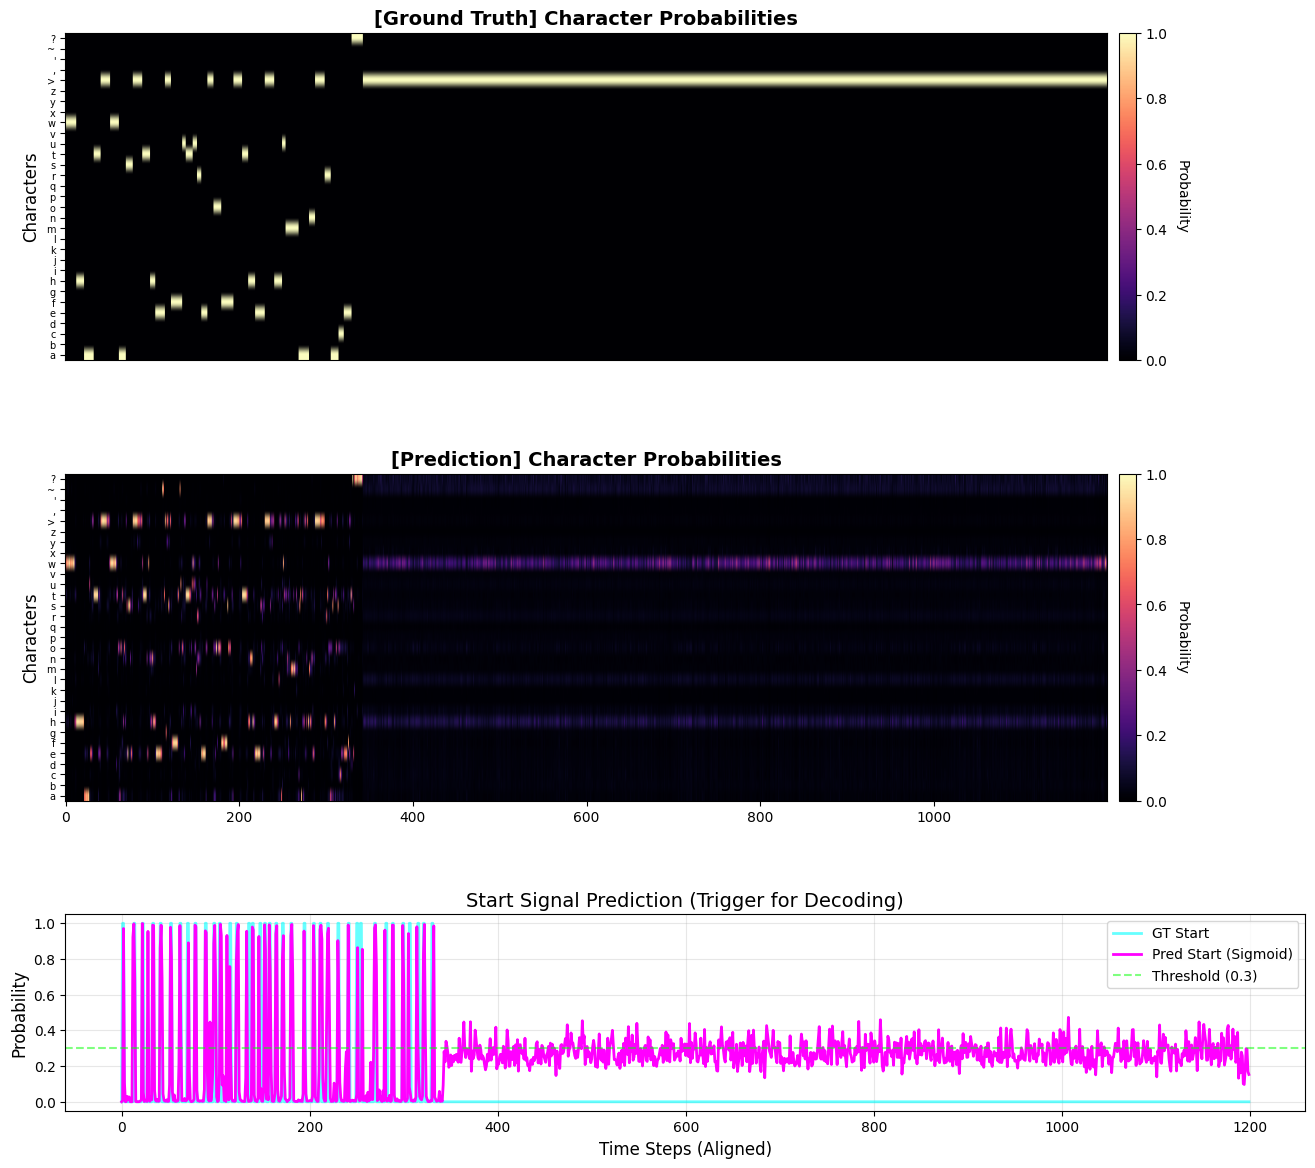

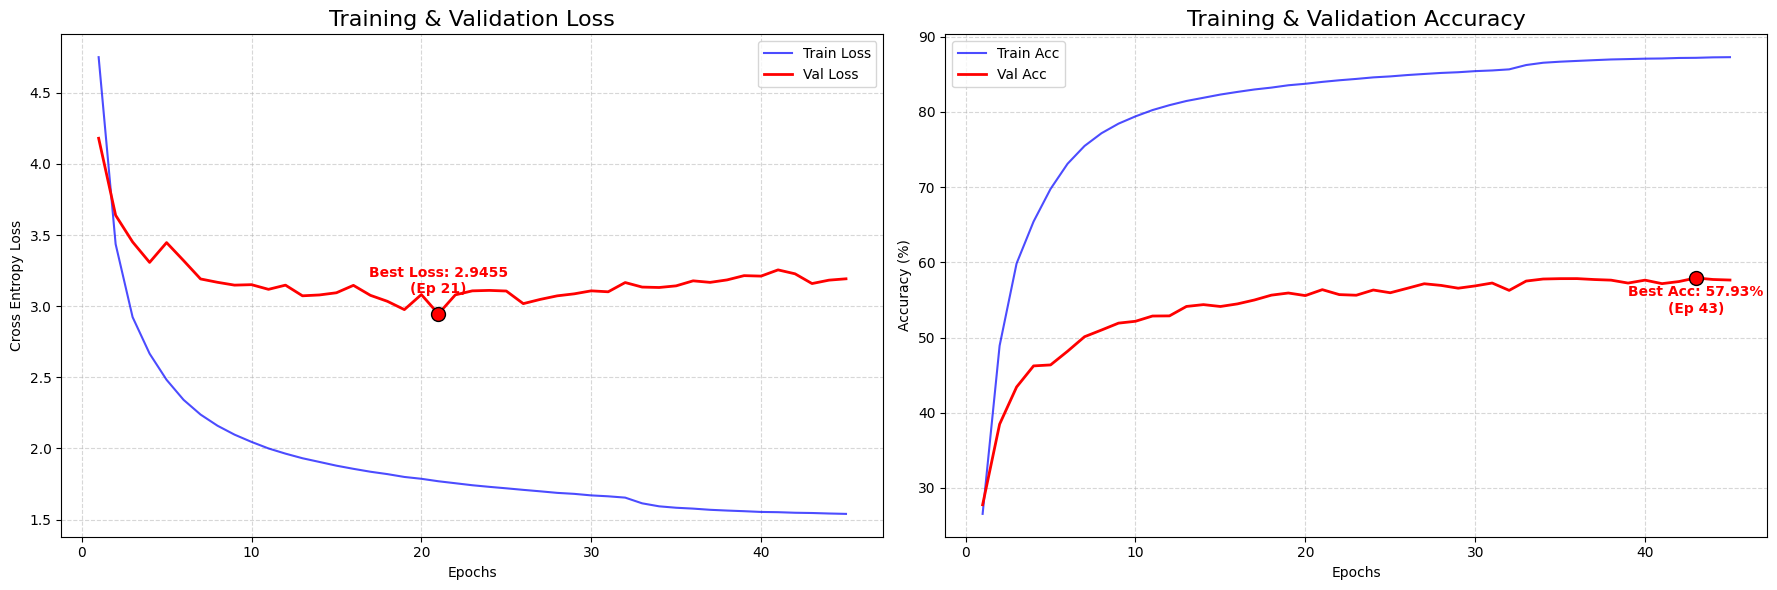


==================== [Whole Test Set Evaluation] ====================
Total Samples: 41
Decoding Threshold: 0.3
-----------------------------------------------------------------
[01] Target: even the compost heap had corpses in it
     Pred  : evee the osmpect hesp pds scnpesesldin itd
[02] Target: i auditioned and he hired me
     Pred  : i auditidned ard hh hred he
[03] Target: i bought her chocolate for her last week
     Pred  : i ltougwts ler sbeovote ef eerohler lous t mweehr
[04] Target: she inhaled deeply, like a participant in a yoga class
     Pred  : she iiindhealed dedeyply, like c apgnticipant in aiydgaa dclaes
[05] Target: heroes represent individuals of exceptional prowess and courage
     Pred  : heeeeys  nepngsent individuuals of e esyeptiopna  prewesnse and oouraae
[06] Target: inside jake's duffel bag, a knife and a large sledgehammer
     Pred  : ihnside aysee'' eefgfelh bpea a eec knife dnd  de  llearge slledgelherlereiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiiii

In [ ]:
import torch
import os

# 경로 설정
checkpoint_dir = '/content/drive/MyDrive/handwritingBCI_data/model_checkpoints'
best_ckpt_path = os.path.join(checkpoint_dir, 'adaptive_transformer_best.pth')
last_ckpt_path = os.path.join(checkpoint_dir, 'adaptive_transformer_last.pth')

# --- [A] 모델 가중치 로드 (Best Model 사용) ---
if os.path.exists(last_ckpt_path):
    checkpoint_best = torch.load(last_ckpt_path, map_location=device)
    model.load_state_dict(checkpoint_best['state_dict'])
    print(f"[Best Model Weights] 로드 성공 (Ep: {checkpoint_best.get('epoch', '알 수 없음')})")
else:
    print(f"Best 모델 파일을 찾을 수 없습니다: {last_ckpt_path}")

# --- [B] 학습 곡선 데이터 로드 (Last Model 사용) ---
if os.path.exists(last_ckpt_path):
    checkpoint_last = torch.load(last_ckpt_path, map_location=device)
    # 전체 학습 기록은 Last 모델의 체크포인트에 가장 최신화되어 있습니다.
    history = checkpoint_last.get('history', {
        'train_loss': checkpoint_last.get('losses', []),
        'val_loss': [], 'train_acc': [], 'val_acc': []
    })
    print(f"[Full History] 로드 성공 (최종 Ep: {checkpoint_last.get('epoch', '알 수 없음')})")
else:
    print(f"Last 모델 파일을 찾을 수 없습니다: {last_ckpt_path}")
    # 만약 Last가 없다면 Best의 history라도 가져옵니다.
    history = checkpoint_best.get('history', history) if 'checkpoint_best' in locals() else history


# 1. 시각화 (히트맵)
visualize_ce_output(model, test_set, device=device, threshold=0.3)

# 2. 학습 곡선
plot_metrics(history)

# 3. 텍스트 추론 결과
evaluate_whole_testset(model, test_set, device=device, threshold=0.3)

# 현재 모델의 g 값 분포 확인
analyze_confidence(model)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import copy
import numpy as np
import jiwer

# g-Guided Test-Time Adaptation 함수
def test_time_adaptation_g_guided(original_model, dataset, device='cuda', threshold=0.1, lr=1e-5, steps=1):
    """
    g값(Standard Attention 비중)을 신뢰도 지표로 사용하여,
    모델이 '문맥적 확신'을 가질 때만 Encoder(to_patch_embedding)를 강력하게 튜닝합니다.
    """

    # 모델 복사
    model = copy.deepcopy(original_model)
    model.to(device)
    model.train()

    # 오직 Encoder(to_patch_embedding)만 업데이트
    params_to_update = []
    for name, param in model.named_parameters():
        if 'to_patch_embedding' in name:  # NeuralTransformer의 인코더 레이어 이름
            param.requires_grad = True
            params_to_update.append(param)
        else:
            param.requires_grad = False # 나머지는 동결(Freeze)

    optimizer = optim.Adam(params_to_update, lr=lr)

    predictions = []
    references = []

    print(f"\n{'='*15} [Running g-Guided TTA] {'='*15}")
    print(f"Entropy Minimization weighted by 'g' (Context Confidence)")
    print(f"Strategy: Update ONLY if Last-Layer g > 0.65 (High Context Confidence)")
    print(f"Updating Layer: to_patch_embedding (Encoder)")

    for i in range(len(dataset)):
        inputs, targets, true_text = dataset[i]
        inputs = inputs.unsqueeze(0).to(device)

        # 정답 텍스트 정리
        clean_target = true_text.replace('>', ' ').replace('~', '').strip()

        # --- [Step 1] Adaptation (Unsupervised) ---
        skipped = False
        mean_g = 0.0
        final_loss = 0.0

        # 테스트 데이터 하나에 대해 반복 학습 (Instance-wise Adaptation)
        for _ in range(steps):
            optimizer.zero_grad()

            # Forward Pass
            char_logits, start_logits = model(inputs)

            # (1) Last Layer의 g값만 추출 (가장 확실한 판단)
            g_values = []

            last_layer = model.transformer.layers[-1][0] # AdaptiveAttention

            if hasattr(last_layer, 'last_g') and last_layer.last_g is not None:
                # [Batch, Heads, 1, 1] -> 평균
                mean_g = last_layer.last_g.mean().item()
            else:
                mean_g = 0.5 # Fallback

            # (2) Strict Filtering (문지기)
            # g가 0.65 미만이면 신호 의존도가 높거나 헷갈리는 상태 -> 업데이트 Skip
            if mean_g < 0.65:
                skipped = True
                break

            # (3) Entropy Calculation
            char_probs = torch.softmax(char_logits, dim=-1)
            entropy = -torch.sum(char_probs * torch.log(char_probs + 1e-6), dim=-1).mean()

            # (4) Safety: 엔트로피가 너무 높으면(너무 모르면) 업데이트 금지
            if entropy.item() > 1.5: # 1.5는 경험적 수치
                skipped = True
                break

            # Loss & Update
            loss = entropy # g를 곱하지 않고, g는 gate로만 사용
            loss.backward()
            optimizer.step()
            final_loss = loss.item()

        # Inference (Prediction)
        model.eval()
        with torch.no_grad():
            char_logits, start_logits = model(inputs)

            # Decoding
            pred_text = greedy_decode(char_logits.squeeze(0), start_logits.squeeze(0), threshold=threshold, min_dist=6)

            clean_target = true_text.replace('>', ' ').replace('~', '').strip()
            clean_pred = pred_text.replace('>', ' ').replace('~', '').strip()

            predictions.append(clean_pred)
            references.append(clean_target)

            # 로그 출력 (g값과 Loss 확인)
            status = "SKIPPED" if skipped else "UPDATED"
            print(f"[{i+1:02d}] {status} (g={mean_g:.2f}) | Loss: {final_loss:.4f}")
            print(f"     GT  : {clean_target}")
            print(f"     Pred: {clean_pred}")
            print("-" * 50)

        model.train() # 다음 샘플 Adaptation을 위해 다시 Train 모드

    # 최종 평가
    total_cer = jiwer.cer(references, predictions)
    print("=" * 65)
    print(f" g-Guided TTA Adapted CER: {total_cer:.4f} ({total_cer*100:.2f}%)")
    print("=" * 65)

In [ ]:
# LR은 매우 작게 시작하는 것이 안전합니다 (1e-5 ~ 1e-6)
test_time_adaptation_g_guided(model, test_set, device=device, lr=1e-6, steps=1)


=============== [Running g-Guided TTA] ===============
Entropy Minimization weighted by 'g' (Context Confidence)
Strategy: Update ONLY if Last-Layer g > 0.65 (High Context Confidence)
Updating Layer: to_patch_embedding (Encoder)
[01] SKIPPED (g=0.46) | Loss: 0.0000
     GT  : even the compost heap had corpses in it
     Pred: evee the osmpect hesp pdts scnpesesldin itd
--------------------------------------------------
[02] SKIPPED (g=0.46) | Loss: 0.0000
     GT  : i auditioned and he hired me
     Pred: i auditidned ard h hred he
--------------------------------------------------
[03] SKIPPED (g=0.44) | Loss: 0.0000
     GT  : i bought her chocolate for her last week
     Pred: ii ltoug wets lher sboeov olo te oef erohler loues t mweehr
--------------------------------------------------
[04] SKIPPED (g=0.41) | Loss: 0.0000
     GT  : she inhaled deeply, like a participant in a yoga class
     Pred: she iindhealed dedeyply, like c ap gnlticipant ain aiydga dclaes
--------------------

In [ ]:
def count_parameters(model):
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    print(f"========================================")
    print(f" Total Parameters: {total_params:,}")
    print(f" Trainable Params: {trainable_params:,}")
    print(f" Non-trainable   : {total_params - trainable_params:,}")
    print(f"========================================")
    return total_params, trainable_params

count_parameters(model)

 Total Parameters: 11,892,896
 Trainable Params: 11,892,896
 Non-trainable   : 0


(11892896, 11892896)

In [ ]:
import time
import torch
import numpy as np

def measure_inference_speed(model, device='cuda', input_shape=(1, 12000, 192), repetitions=100):
    model.eval()
    model.to(device)

    # 더미 입력 데이터 생성
    dummy_input = torch.randn(*input_shape).to(device)

    # 1. Warm-up (GPU 예열)
    print("🔥 Warming up GPU...")
    with torch.no_grad():
        for _ in range(10):
            _ = model(dummy_input)

    # 2. 실제 측정
    print(f"⏱️ Measuring inference time over {repetitions} runs...")
    timings = []

    with torch.no_grad():
        for _ in range(repetitions):
            # GPU 동기화 (시작)
            if device == 'cuda': torch.cuda.synchronize()
            start_time = time.time()

            # 추론 실행
            _ = model(dummy_input)

            # GPU 동기화 (끝)
            if device == 'cuda': torch.cuda.synchronize()
            end_time = time.time()

            timings.append((end_time - start_time) * 1000) # 밀리초(ms) 단위 변환

    # 3. 결과 출력
    avg_time = np.mean(timings)
    std_time = np.std(timings)
    fps = 1000 / avg_time

    print(f"========================================")
    print(f" Inference Latency (Batch Size {input_shape[0]}):")
    print(f"   Mean: {avg_time:.2f} ms")
    print(f"   Std : {std_time:.2f} ms")
    print(f"   FPS : {fps:.2f}")
    print(f"========================================")

    return avg_time

# 사용 예시
measure_inference_speed(model, device=device)

🔥 Warming up GPU...
⏱️ Measuring inference time over 100 runs...
 Inference Latency (Batch Size 1):
   Mean: 8.67 ms
   Std : 0.28 ms
   FPS : 115.27


np.float64(8.674967288970947)